In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as ps

pd.set_option('display.max_columns',None)

In [3]:
train_df = pd.read_csv(r'C:\Users\RISHABH\OneDrive\Desktop\Predicting Airline Satisfaction kaggle comption\processed_data\train_data.csv')

In [4]:
test_df = pd.read_csv(r'C:\Users\RISHABH\OneDrive\Desktop\Predicting Airline Satisfaction kaggle comption\processed_data\test_data.csv')

In [5]:
train_df.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [6]:
test_df.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,3,2,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,5,1,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,4,3,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,3,3,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,2,2,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


In [7]:
train_df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
id,699635.0,349817.000000,201967.372130,0.0,174908.5,349817.0,524725.5,699634.0
Age,699635.0,39.001928,13.800943,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,1353.778702,954.422566,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,699635.0,2.778722,1.280419,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,3.156210,1.475390,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,2.813240,1.329550,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,3.013734,1.254014,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,3.265644,1.300202,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,3.364156,1.288538,0.0,2.0,4.0,4.0,5.0
Seat comfort,699635.0,3.568950,1.275333,0.0,3.0,4.0,5.0,5.0


In [8]:
train_df.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='str')

In [9]:
train_df['satisfaction'].value_counts()

satisfaction
False    389296
True     310339
Name: count, dtype: int64

Before engineering features, I want to understand which travel contexts are already strongly associated with satisfaction. In particular, I look at type of travel, class, and customer loyalty.

In [10]:
for col in ["Type of Travel", "Class", "Customer Type", "Gender"]:
    summary = (
        train_df.groupby(col, dropna=False)['satisfaction']
        .agg(['mean', 'count'])
        .sort_values('mean', ascending=False)
    )
    summary['mean'] = summary['mean'].round(4)
    print(f'\nSatisfaction by {col}')
    display(summary)


Satisfaction by Type of Travel


,mean,count
Type of Travel,,
Business travel,0.5843,497441
Personal Travel,0.0973,202194



Satisfaction by Class


,mean,count
Class,,
Business,0.7253,342212
Eco Plus,0.2422,30019
Eco,0.1676,327404



Satisfaction by Customer Type


,mean,count
Customer Type,,
Loyal Customer,0.4951,576990
disloyal Customer,0.2009,122645



Satisfaction by Gender


,mean,count
Gender,,
Male,0.4491,351683
Female,0.4380,347952


In [11]:
service_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
]

rating_summary = pd.DataFrame({
    'mean_all' : train_df[service_cols].mean(),
    'mean_satisfied' : train_df.loc[train_df.satisfaction == True, service_cols].mean(),
    'mean_unsatisfied' : train_df.loc[train_df.satisfaction == False , service_cols].mean()
})
rating_summary['gap'] = rating_summary['mean_satisfied'] - rating_summary['mean_unsatisfied']

rating_summary.sort_values('gap',ascending=False)

,mean_all,mean_satisfied,mean_unsatisfied,gap
Online boarding,3.364156,4.171732,2.720372,1.451359
Inflight entertainment,3.453910,4.085030,2.950793,1.134236
Seat comfort,3.568950,4.142428,3.111784,1.030644
Cleanliness,3.380401,3.865376,2.993789,0.871587
On-board service,3.517404,3.998199,3.134124,0.864075
Leg room service,3.472847,3.943056,3.098005,0.845051
Inflight wifi service,2.778722,3.196434,2.445730,0.750703
Checkin service,3.420291,3.758989,3.150287,0.608703
Food and drink,3.265644,3.583188,3.012505,0.570683
Baggage handling,3.805443,4.117426,3.556736,0.560691


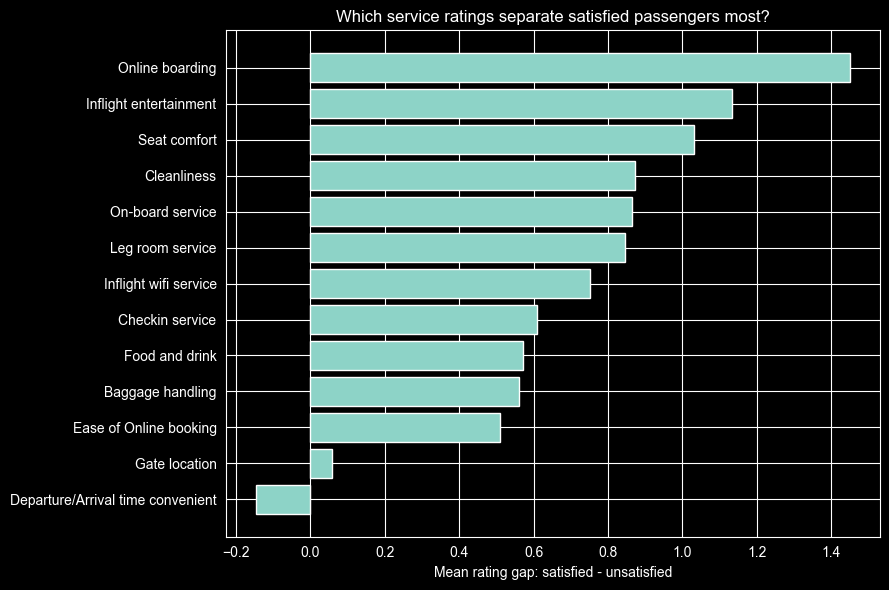

In [12]:
tmp = rating_summary.sort_values("gap")
plt.figure(figsize=(9, 6))
plt.barh(tmp.index, tmp["gap"])
plt.xlabel("Mean rating gap: satisfied - unsatisfied")
plt.title("Which service ratings separate satisfied passengers most?")
plt.tight_layout()
plt.show()